
# Tomato Plant Disease Classification Using CNN

## 1. Research Overview

This project aims to develop a Convolutional Neural Network (CNN)
for automatic classification of tomato plant diseases using
leaf images.

## 2. Research Objectives

1. Explore and understand the tomato disease image dataset.
2. Develop a CNN architecture using TensorFlow and Keras.
3. Investigate image preprocessing and data augmentation.
4. Train and optimize the CNN model.
5. Evaluate classification performance using scientific metrics.
6. Investigate model interpretability using Grad-CAM.
7. Compare different deep learning architectures.

## 3. Dataset Structure

Tomato Plant Diseases Augmented/
    dataset/
        train/
        valid/

## 4. Research Questions

- How accurately can CNN classify tomato plant diseases?
- Does data augmentation improve model generalization?
- Which disease classes are difficult to distinguish?
- Which image regions influence CNN predictions?
- How can model performance and reliability be improved?

## 5. Technologies

- Python
- Jupyter Notebook
- TensorFlow / Keras
- NumPy
- Pandas
- Matplotlib
- Seaborn
- Scikit-learn

## 6. Research Methodology

Dataset Inspection → Exploratory Data Analysis →
Preprocessing → CNN Architecture → Training →
Evaluation → Explainable AI → Experimental Comparison

## 7. Expected Outcome

A trained and evaluated deep learning model capable
of classifying tomato plant diseases from leaf images.


In [39]:
#Configure CPU-only execution
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

import tensorflow as tf

try:
    tf.config.set_visible_devices([], "GPU")
except RuntimeError:
    print("Devices already initialized; restart kernel to apply CPU-only settings.")

try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print("Thread settings already initialized; continuing.")

print("TensorFlow:", tf.__version__)
print("CPU:", tf.config.list_physical_devices("CPU"))
print("GPU:", tf.config.list_physical_devices("GPU"))

Thread settings already initialized; continuing.
TensorFlow: 2.21.0
CPU: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
GPU: []


In [40]:
# Imports and reproducibility
from pathlib import Path
import json
import hashlib
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError

from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support
)

from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [41]:
# Define dataset paths

DATASET_DIR = Path(r"D:\NN\Tomato Plant Diseases Augmented\dataset")

TRAIN_DIR = DATASET_DIR / "train"
VALID_DIR = DATASET_DIR / "valid"

# Use these dimensions consistently in loading, augmentation, and model input.
IMG_SIZE = (160, 160)
INPUT_SHAPE = (160, 160, 3)

BATCH_SIZE = 16
EPOCHS = 20
LEARNING_RATE = 1e-3

OUTPUT_DIR = Path("tomato_cnn_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_DIR.resolve())
print("Train folder exists:", TRAIN_DIR.exists())
print("Valid folder exists:", VALID_DIR.exists())
print("IMG_SIZE:", IMG_SIZE)

Dataset: D:\NN\Tomato Plant Diseases Augmented\Dataset
Train folder exists: True
Valid folder exists: True
IMG_SIZE: (160, 160)


In [42]:
# Inspect dataset classes
if not TRAIN_DIR.exists():
    raise FileNotFoundError(f"Training folder not found: {TRAIN_DIR}")
if not VALID_DIR.exists():
    raise FileNotFoundError(f"Validation folder not found: {VALID_DIR}")

train_classes = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
valid_classes = sorted(p.name for p in VALID_DIR.iterdir() if p.is_dir())

if not train_classes:
    raise ValueError("No class folders found in the training directory.")
if train_classes != valid_classes:
    raise ValueError(f"Train/validation class folders differ: {train_classes} vs {valid_classes}")

CLASS_NAMES = train_classes
NUM_CLASSES = len(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)
for i, name in enumerate(CLASS_NAMES):
    print(i, name)

Number of classes: 10
0 Tomato___Bacterial_spot
1 Tomato___Early_blight
2 Tomato___Late_blight
3 Tomato___Leaf_Mold
4 Tomato___Septoria_leaf_spot
5 Tomato___Spider_mites Two-spotted_spider_mite
6 Tomato___Target_Spot
7 Tomato___Tomato_Yellow_Leaf_Curl_Virus
8 Tomato___Tomato_mosaic_virus
9 Tomato___healthy


,class_name,train_images,valid_images
0,Tomato___Bacterial_spot,1702,425
1,Tomato___Early_blight,1920,480
2,Tomato___Late_blight,1851,463
3,Tomato___Leaf_Mold,1882,470
4,Tomato___Septoria_leaf_spot,1745,436
5,Tomato___Spider_mites Two-spotted_spider_mite,1741,435
6,Tomato___Target_Spot,1827,457
7,Tomato___Tomato_Yellow_Leaf_Curl_Virus,1961,490
8,Tomato___Tomato_mosaic_virus,1790,448
9,Tomato___healthy,1926,481


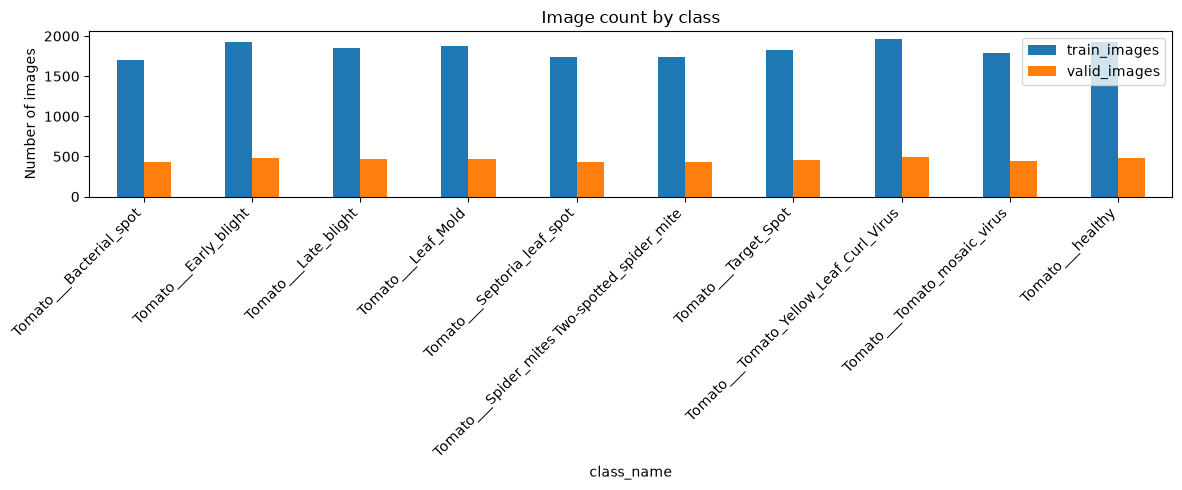

Training total: 18345
Validation total: 4585


In [43]:
# Count images in each class
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

def count_images_by_class(folder):
    return {
        p.name: sum(
            1 for f in p.rglob("*")
            if f.is_file() and f.suffix.lower() in IMAGE_EXTENSIONS
        )
        for p in sorted(folder.iterdir()) if p.is_dir()
    }

train_counts = count_images_by_class(TRAIN_DIR)
valid_counts = count_images_by_class(VALID_DIR)

distribution_df = pd.DataFrame({
    "class_name": CLASS_NAMES,
    "train_images": [train_counts[c] for c in CLASS_NAMES],
    "valid_images": [valid_counts[c] for c in CLASS_NAMES]
})
display(distribution_df)

distribution_df.set_index("class_name").plot(
    kind="bar", figsize=(12, 5), title="Image count by class"
)
plt.ylabel("Number of images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Training total:", sum(train_counts.values()))
print("Validation total:", sum(valid_counts.values()))

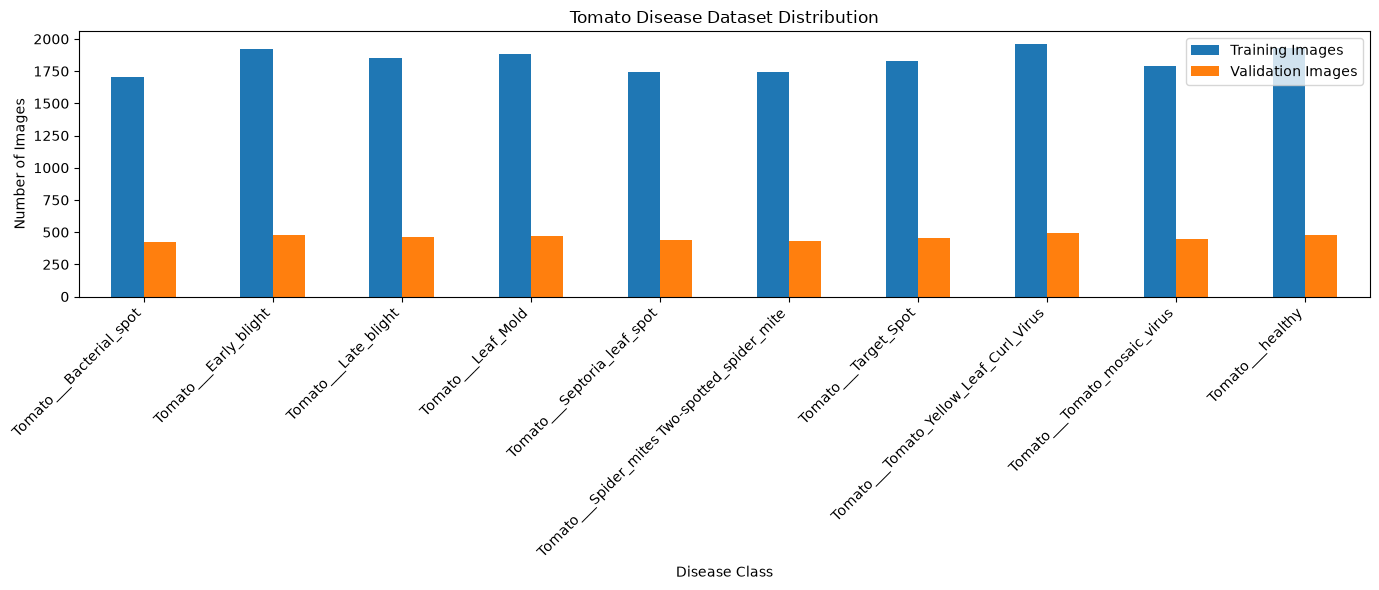

In [30]:
# Visualize class distribution
distribution.plot(
    x="Class",
    y=["Training Images", "Validation Images"],
    kind="bar",
    figsize=(14, 6)
)

plt.title("Tomato Disease Dataset Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [31]:
# Load images into TensorFlow
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

valid_ds = keras.utils.image_dataset_from_directory(
    VALID_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False,
    seed=SEED
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

Found 18345 files belonging to 10 classes.
Found 4585 files belonging to 10 classes.
Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
Number of classes: 10


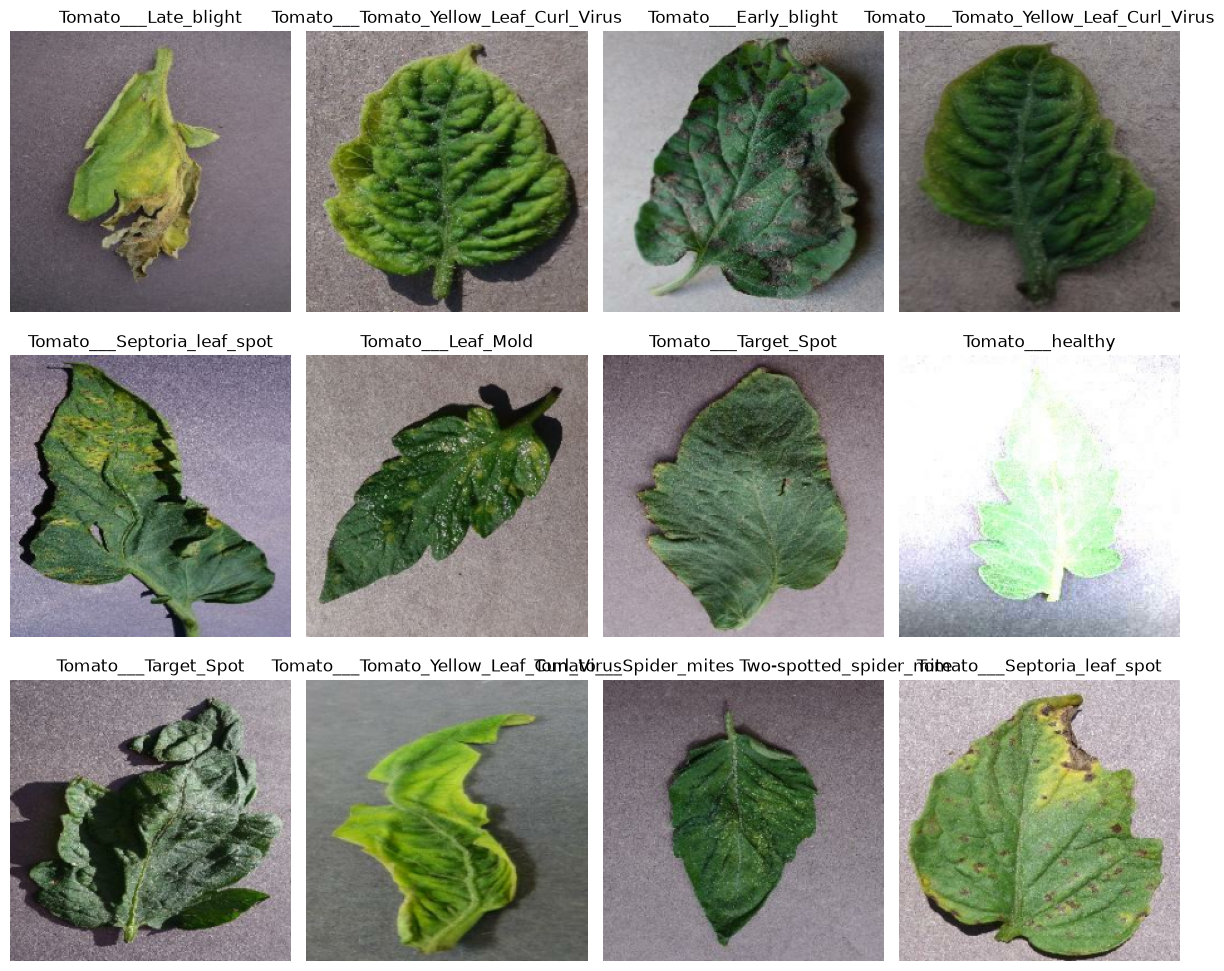

In [32]:
# Visualize actual leaf images
plt.figure(figsize=(12, 10))

for images, labels in train_ds.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [33]:
# Optimize the TensorFlow data pipeline
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
valid_ds = valid_ds.prefetch(buffer_size=AUTOTUNE)

In [34]:
# Understand image normalization
normalization_layer = layers.Rescaling(1./255)

for images, labels in train_ds.take(1):

    normalized_images = normalization_layer(images)

    print("Original minimum:", tf.reduce_min(images).numpy())
    print("Original maximum:", tf.reduce_max(images).numpy())

    print("Normalized minimum:",
          tf.reduce_min(normalized_images).numpy())

    print("Normalized maximum:",
          tf.reduce_max(normalized_images).numpy())

Original minimum: 0.0
Original maximum: 255.0
Normalized minimum: 0.0
Normalized maximum: 1.0


In [35]:
# Data augmentation
# ============================================================
# DATA AUGMENTATION
# ============================================================

IMG_SIZE = (160, 160)

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ],
    name="data_augmentation"
)

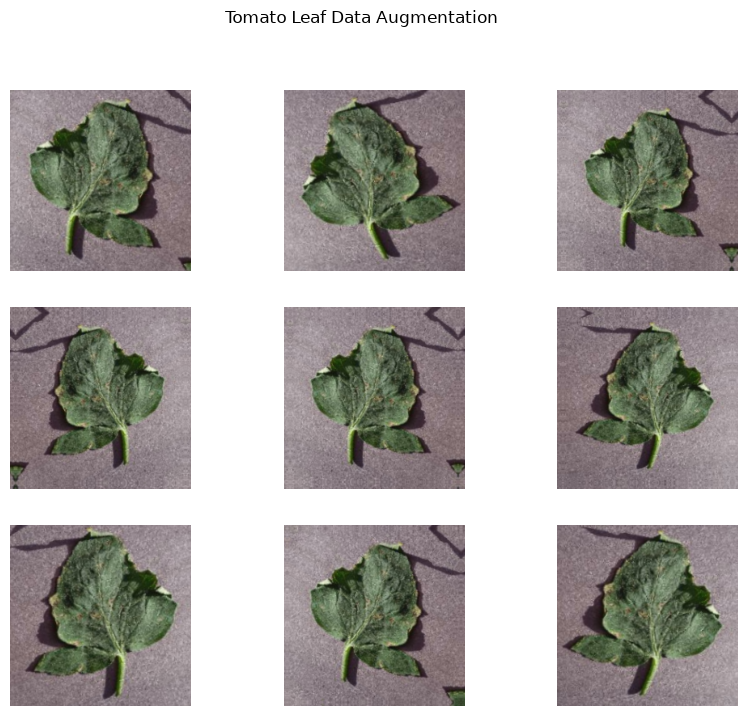

In [36]:
# Visualize augmentation:
for images, labels in train_ds.take(1):

    sample_image = images[0]

    plt.figure(figsize=(10, 8))

    for i in range(9):
        augmented = data_augmentation(
            tf.expand_dims(sample_image, 0),
            training=True
        )

        plt.subplot(3, 3, i + 1)
        plt.imshow(
            tf.clip_by_value(augmented[0] / 255., 0, 1)
        )
        plt.axis("off")

    plt.suptitle("Tomato Leaf Data Augmentation")
    plt.show()

In [37]:
# Define CNN model

# ============================================================
# 1. CNN MODEL ARCHITECTURE
# ============================================================

def build_cnn(num_classes, input_shape=(160, 160, 3)):

    # --------------------------------------------------------
    # INPUT LAYER
    # --------------------------------------------------------

    inputs = keras.Input(
        shape=input_shape,
        name="input_image"
    )

    # --------------------------------------------------------
    # DATA PREPROCESSING
    # --------------------------------------------------------

    x = data_augmentation(inputs)

    x = layers.Rescaling(
        scale=1.0 / 255,
        name="normalization"
    )(x)

    # --------------------------------------------------------
    # CONVOLUTIONAL BLOCK 1
    # Feature extraction: basic patterns
    # Filters: 32
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        name="conv_block_1"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="pool_1"
    )(x)

    # --------------------------------------------------------
    # CONVOLUTIONAL BLOCK 2
    # Feature extraction: textures and patterns
    # Filters: 64
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        name="conv_block_2"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="pool_2"
    )(x)

    # --------------------------------------------------------
    # CONVOLUTIONAL BLOCK 3
    # Feature extraction: complex disease features
    # Filters: 128
    # --------------------------------------------------------

    x = layers.Conv2D(
        filters=128,
        kernel_size=(3, 3),
        padding="same",
        activation="relu",
        name="last_conv"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="pool_3"
    )(x)

    # --------------------------------------------------------
    # FEATURE AGGREGATION
    # --------------------------------------------------------

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    # --------------------------------------------------------
    # CLASSIFICATION HEAD
    # --------------------------------------------------------

    x = layers.Dense(
        units=128,
        activation="relu",
        name="classification_dense"
    )(x)

    x = layers.Dropout(
        rate=0.4,
        name="dropout"
    )(x)

    # --------------------------------------------------------
    # OUTPUT LAYER
    # --------------------------------------------------------

    outputs = layers.Dense(
        units=num_classes,
        activation="softmax",
        name="predictions"
    )(x)

    # --------------------------------------------------------
    # BUILD MODEL
    # --------------------------------------------------------

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="Tomato_Disease_CNN"
    )

    return model


# ============================================================
# 2. CREATE MODEL
# ============================================================

model = build_cnn(
    num_classes=NUM_CLASSES,
    input_shape=(160, 160, 3)
)


# ============================================================
# 3. DISPLAY MODEL ARCHITECTURE
# ============================================================

model.summary()


ValueError: Exception encountered when calling Sequential.call().

[1mInput 0 with name 'input_layer_2' of layer 'functional_2' is incompatible with the layer: expected shape=(None, 224, 224, 3), found shape=(None, 160, 160, 3)[0m

Arguments received by Sequential.call():
  • args=('<KerasTensor shape=(None, 160, 160, 3), dtype=float32, sparse=False, ragged=False, name=input_image>',)
  • kwargs={'mask': 'None'}